## Steps

- predict on all examples for rubber in Cambodia (possibly other classes and other countries later)
- get the sum of rubber probabilities on all these examples

- replace all rubber with 0s in tab data
- predict again, and get the sum of rubber probabilities
- is it lower? 
- if yes, try to make a plot that links the tab value with the class prob

In [2]:
import sys
import os
sys.path.append('../')


import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
import pickle
import pprint

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.geometry import box
from shapely.ops import nearest_points

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier
from utils import get_tiles_as_gdf

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

np.set_printoptions(suppress=True)

np.set_printoptions(suppress=True)

In [3]:
wandb_id = 'fuvmj0ci'


In [4]:
device = 'cuda'

model_dir = os.path.join('../models_trained', wandb_id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


#Load trained model
model = MultiModalDriverClassifier(11,  **config)
model = model.to(device)

trained_weights = f'../models_trained/{wandb_id}/last.pt'
_ = model.load_state_dict(torch.load(trained_weights)['state_dict'])
_ = model.eval()



In [5]:
df = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv')

In [6]:
cambodia = df.loc[df.country == 'Cambodia']

In [7]:
cambodia.to_csv('../data/tmp/cambodia_tmp.csv',   index=False)

In [8]:
config['data']['annotation_file'] = '../data/tmp/cambodia_tmp.csv'

In [9]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [38]:
#cambodia['preds'] = preds
#cambodia['preds'] = cambodia['preds'].map(inverse_label_mapping)

/tmp/ipykernel_139306/4161700322.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cambodia['preds'] = cambodia['preds'].map(inverse_label_mapping)


In [10]:
model.eval()

preds_batches = []
targets_batches = []

all_mean_probs = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,8] = expansion_rates_batch[:,8]*coeff



        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


In [11]:
_all_mean_probs = np.stack(all_mean_probs)
coeffs = [coef/10 for coef in range(40)]


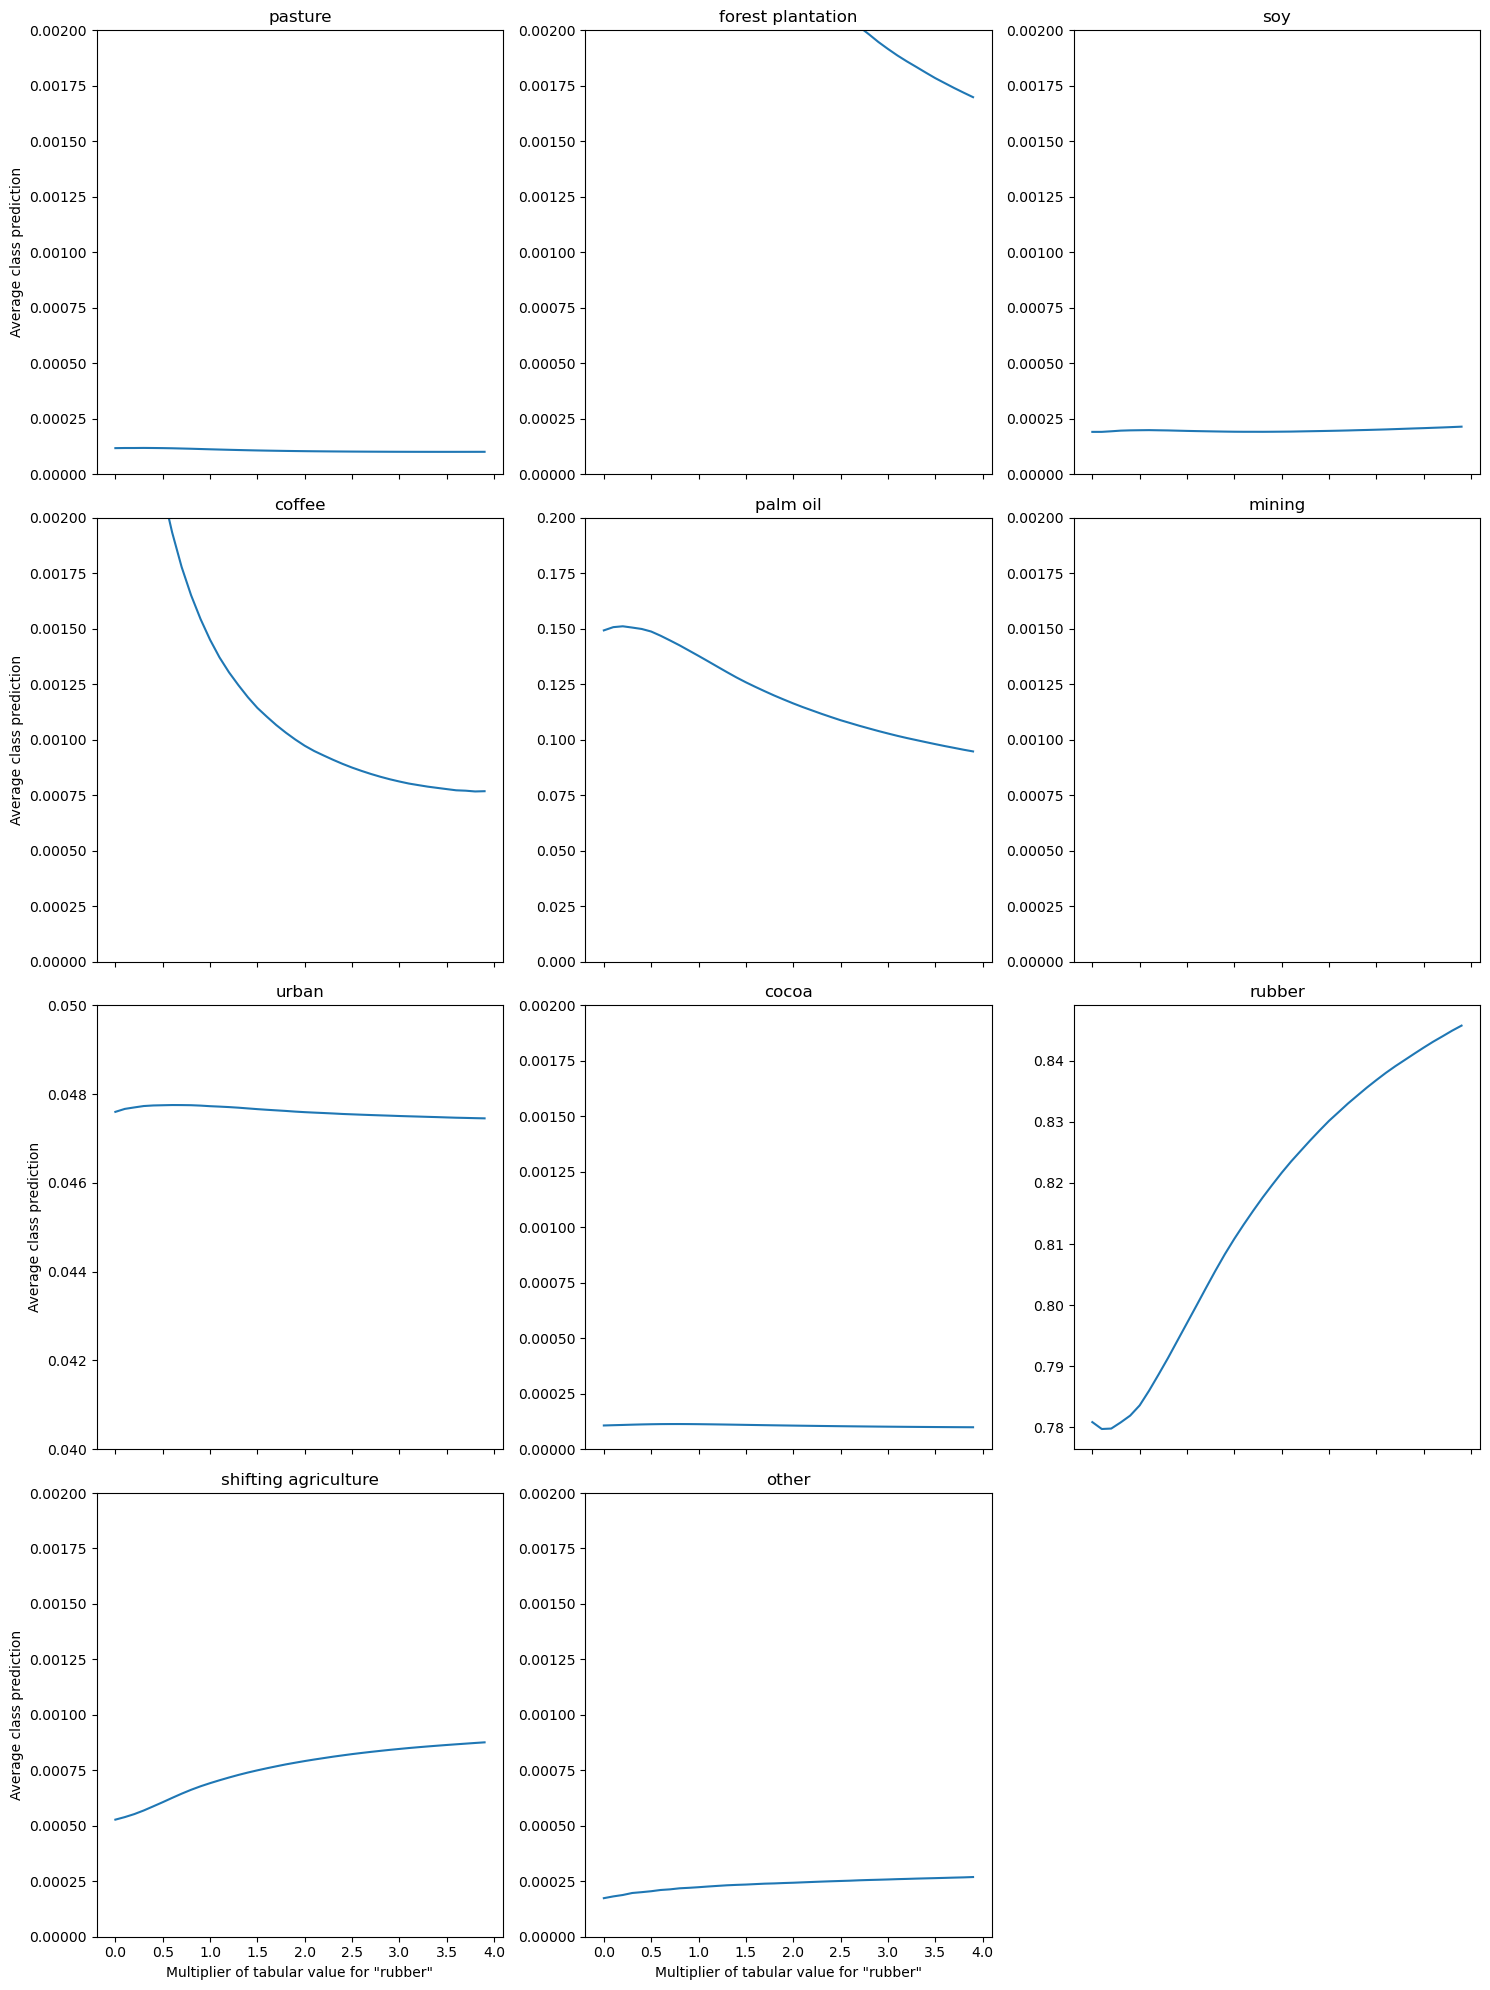

In [12]:
_all_mean_probs = np.stack(all_mean_probs)
coeffs = [coef/10 for coef in range(40)]

# Adjust grid size as needed; here we're using a 4x3 grid to accommodate up to 12 subplots
fig, axs = plt.subplots(4, 3, figsize=(15, 20), sharex=True)

limits = {}

#x_axis_vals = 

# Loop through LABEL_MAPPING and plot each on its own subplot
for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    row = idx // 3
    col = idx % 3
    axs[row, col].plot(coeffs, _all_mean_probs[:, cls_idx])
    axs[row, col].set_title(name)
    if name not in ['rubber']:

        if name == 'palm oil':
            
            axs[row, col].set_ylim(0, 0.2)
        elif name == 'urban':
            axs[row, col].set_ylim(0.04, 0.05)
        else:
            axs[row, col].set_ylim(0, 0.002)
    #axs[row, col].legend(loc='upper right')
    
    #axs[row, col].set_xticks(x_indices)
    #axs[row, col].set_xticklabels(x_axis_vals)
    if idx in [0,3,6,9]:
        axs[row, col].set_ylabel('Average class prediction')
    if idx in [9,10,11]:
        axs[row, col].set_xlabel('Multiplier of tabular value for "rubber"')
    
# Hide any unused subplots if the grid has extra spaces
for i in range(len(LABEL_MAPPING), 12):
    fig.delaxes(axs.flat[i])

#plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()
# Adjust grid size as needed; here we're using a 4x3 grid to accommodate up to 12 subplots
fig, axs = plt.subplots(4, 3, figsize=(15, 20), sharex=True)

limits = {}

#x_axis_vals = 

# Loop through LABEL_MAPPING and plot each on its own subplot
for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    row = idx // 3
    col = idx % 3
    axs[row, col].plot(coeffs, _all_mean_probs[:, cls_idx])
    axs[row, col].set_title(name)
    if name not in ['rubber']:

        if name == 'palm oil':
            
            axs[row, col].set_ylim(0, 0.2)
        elif name == 'urban':
            axs[row, col].set_ylim(0.04, 0.05)
        else:
            axs[row, col].set_ylim(0, 0.002)
    #axs[row, col].legend(loc='upper right')
    
    #axs[row, col].set_xticks(x_indices)
    #axs[row, col].set_xticklabels(x_axis_vals)
    if idx in [0,3,6,9]:
        axs[row, col].set_ylabel('Average class prediction')
    if idx in [9,10,11]:
        axs[row, col].set_xlabel('Multiplier of tabular value for "rubber"')
    
# Hide any unused subplots if the grid has extra spaces
for i in range(len(LABEL_MAPPING), 12):
    fig.delaxes(axs.flat[i])

#plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()

### Average all non-rubber classes


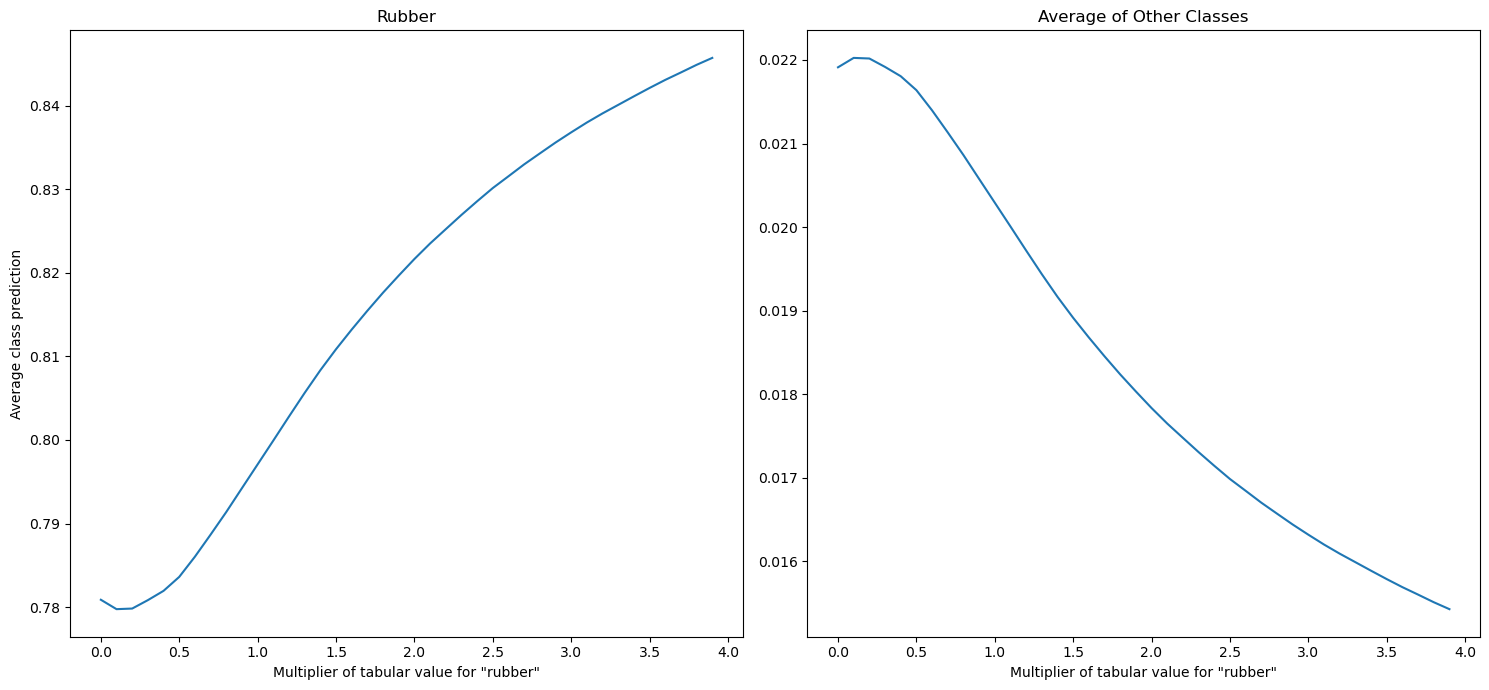

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Adjust grid size for two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)

# Separate 'rubber' and other classes
rubber_idx = LABEL_MAPPING.get('rubber')
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != 'rubber']

# Plot for 'rubber'
axs[0].plot(coeffs, _all_mean_probs[:, rubber_idx])
axs[0].set_title('Rubber')
axs[0].set_ylabel('Average class prediction')
axs[0].set_xlabel('Multiplier of tabular value for "rubber"')

# Plot for average of other classes
average_probs = np.mean(_all_mean_probs[:, other_classes_idx], axis=1)
axs[1].plot(coeffs, average_probs)
axs[1].set_title('Average of Other Classes')
axs[1].set_xlabel('Multiplier of tabular value for "rubber"')

# Tight layout
plt.tight_layout()
plt.show()

### Palm oil - Cambodia

In [15]:
model.eval()

preds_batches = []
targets_batches = []

all_mean_probs_palm_oil = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,4] = expansion_rates_batch[:,4]*coeff



        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs_palm_oil.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


In [17]:
_all_mean_probs_palm_oil = np.stack(all_mean_probs_palm_oil)


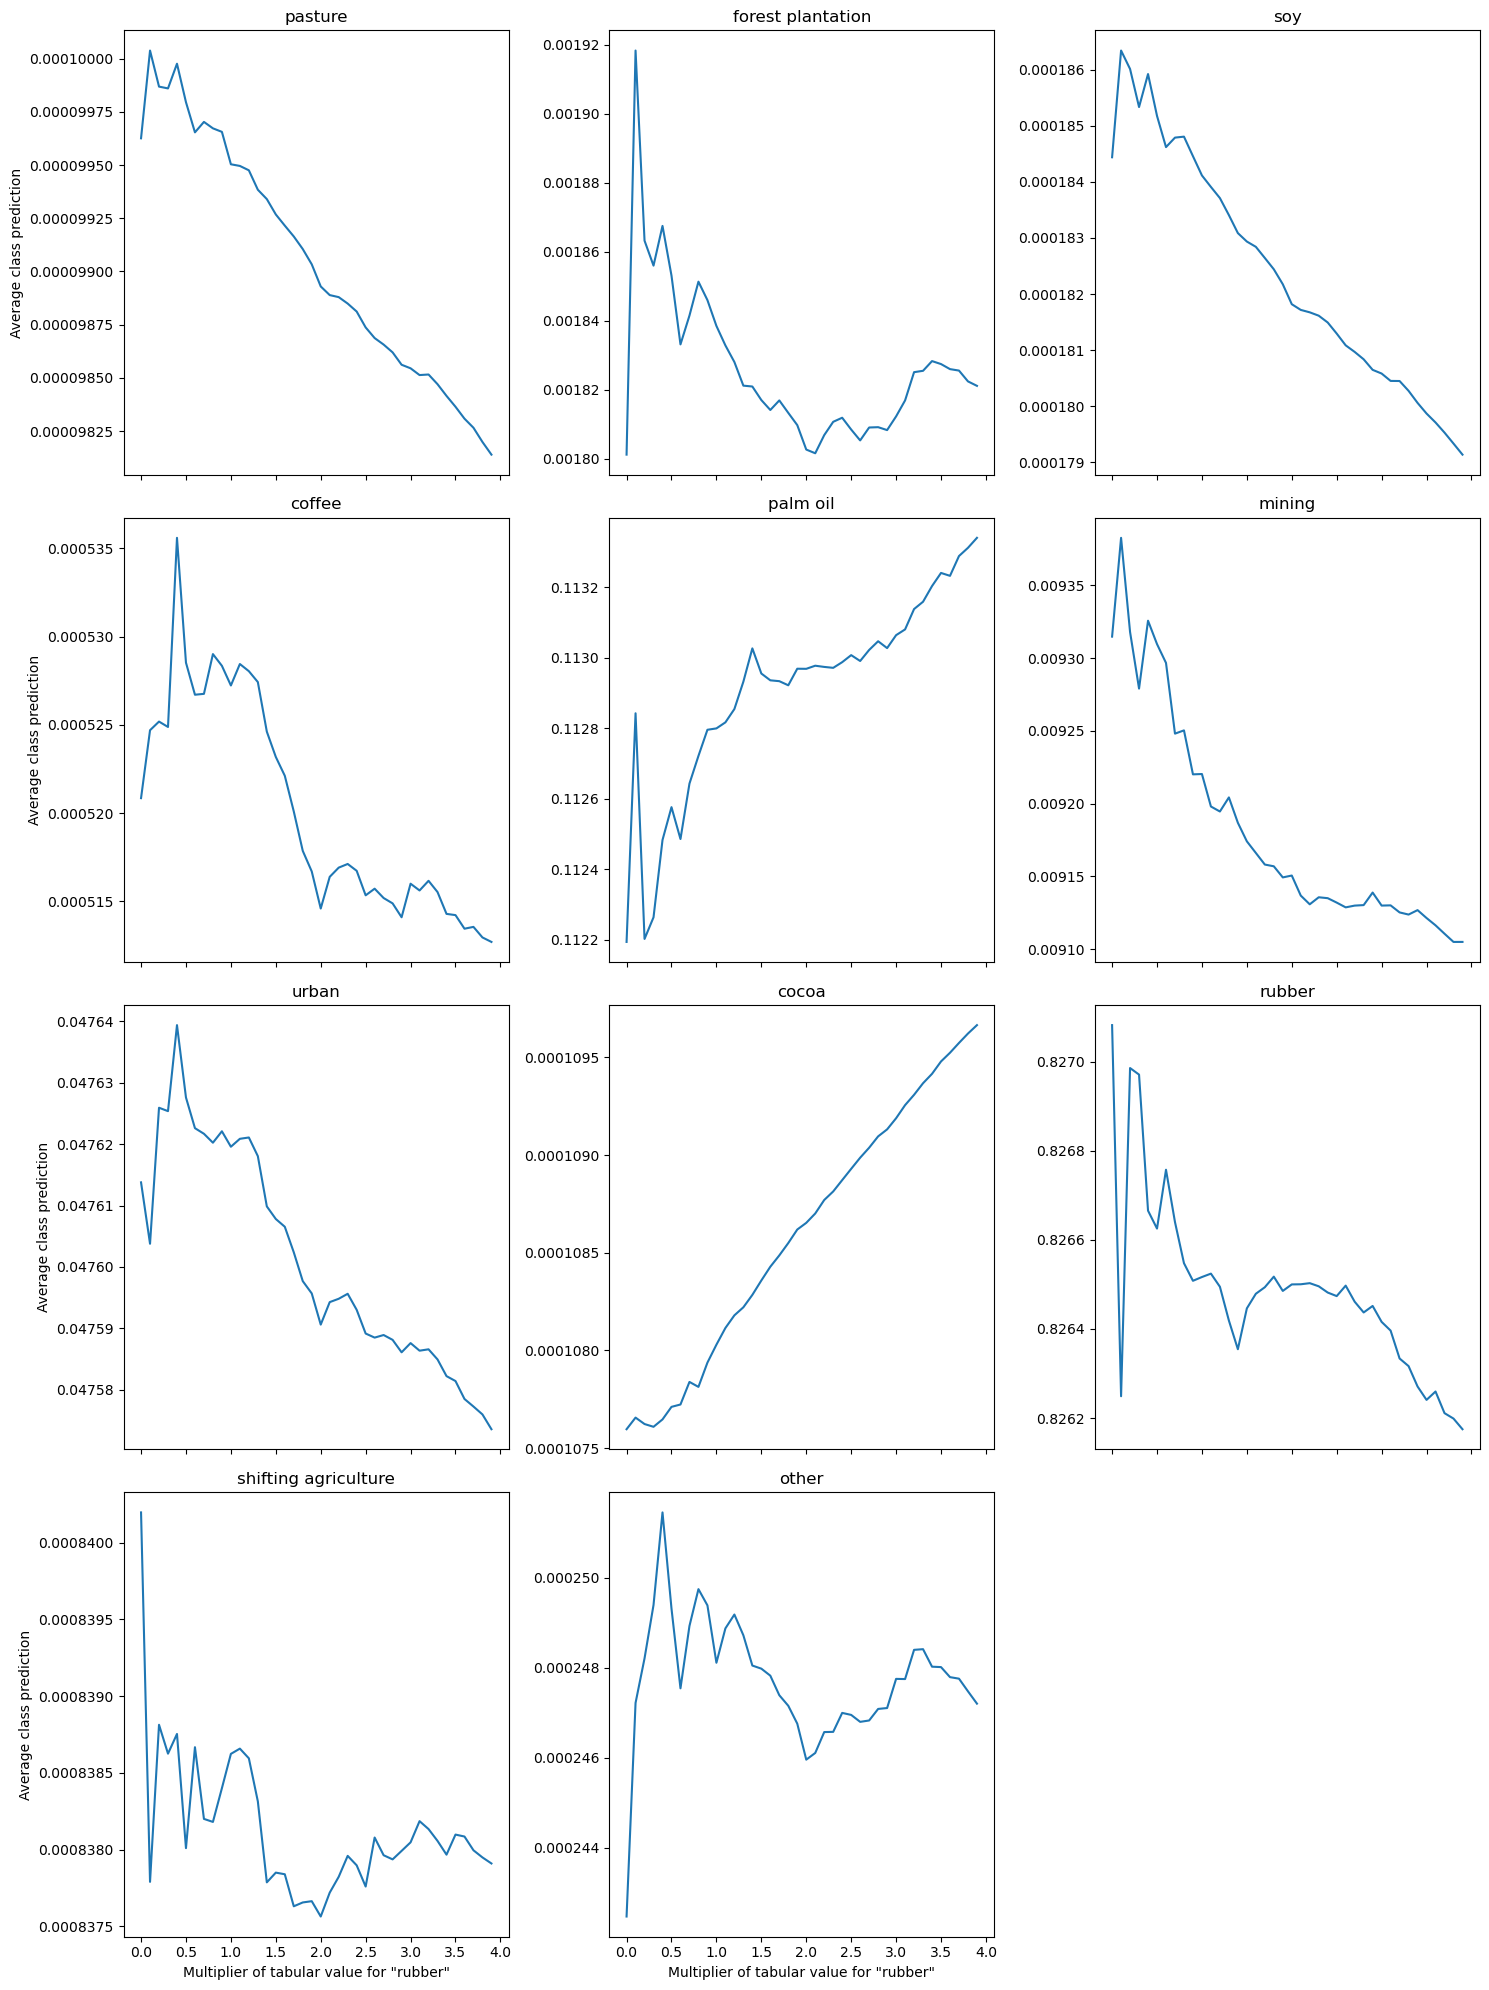

In [18]:
import matplotlib.pyplot as plt

# Adjust grid size as needed; here we're using a 4x3 grid to accommodate up to 12 subplots
fig, axs = plt.subplots(4, 3, figsize=(15, 20), sharex=True)

limits = {}

#x_axis_vals = 

# Loop through LABEL_MAPPING and plot each on its own subplot
for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    row = idx // 3
    col = idx % 3
    axs[row, col].plot(coeffs, _all_mean_probs_palm_oil[:, cls_idx])
    axs[row, col].set_title(name)
    '''if name not in ['rubber']:

        if name == 'palm oil':
            
            axs[row, col].set_ylim(0, 0.2)
        elif name == 'urban':
            axs[row, col].set_ylim(0.04, 0.05)
        else:
            axs[row, col].set_ylim(0, 0.002)'''
    #axs[row, col].legend(loc='upper right')
    
    #axs[row, col].set_xticks(x_indices)
    #axs[row, col].set_xticklabels(x_axis_vals)
    if idx in [0,3,6,9]:
        axs[row, col].set_ylabel('Average class prediction')
    if idx in [9,10,11]:
        axs[row, col].set_xlabel('Multiplier of tabular value for "rubber"')
    
# Hide any unused subplots if the grid has extra spaces
for i in range(len(LABEL_MAPPING), 12):
    fig.delaxes(axs.flat[i])

#plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()

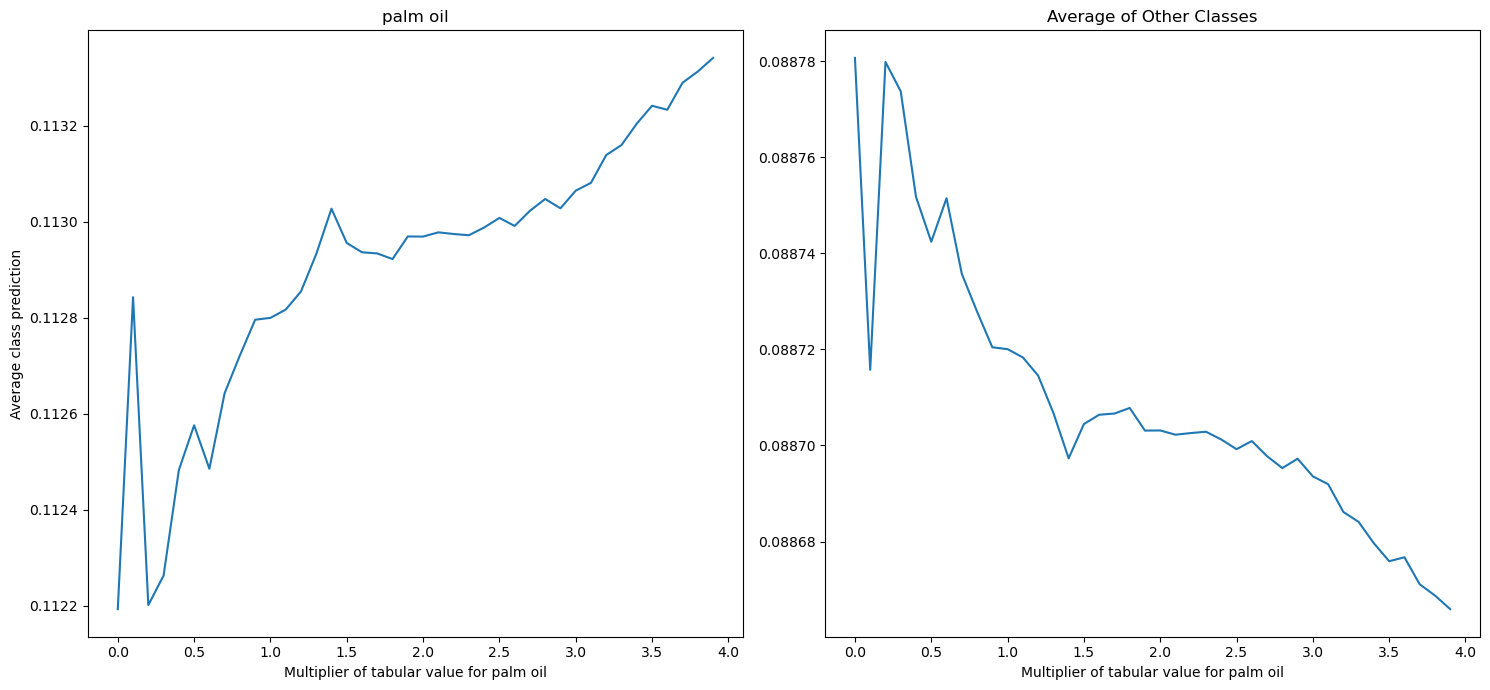

In [20]:
import matplotlib.pyplot as plt
import numpy as np

cls_name = 'palm oil'

# Adjust grid size for two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)

# Separate 'rubber' and other classes
palm_oil_index = LABEL_MAPPING.get(cls_name)
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != cls_name]

# Plot for 'rubber'
axs[0].plot(coeffs, _all_mean_probs_palm_oil[:, palm_oil_index])
axs[0].set_title(cls_name)
axs[0].set_ylabel('Average class prediction')
axs[0].set_xlabel(f'Multiplier of tabular value for {cls_name}')

# Plot for average of other classes
average_probs = np.mean(_all_mean_probs_palm_oil[:, other_classes_idx], axis=1)
axs[1].plot(coeffs, average_probs)
axs[1].set_title('Average of Other Classes')
axs[1].set_xlabel(f'Multiplier of tabular value for {cls_name}')

# Tight layout
plt.tight_layout()
plt.show()

### Non-commodity value - let's try

In [21]:
model.eval()

preds_batches = []
targets_batches = []

all_mean_probs_mining = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,5] = expansion_rates_batch[:,5]*coeff


        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs_mining.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


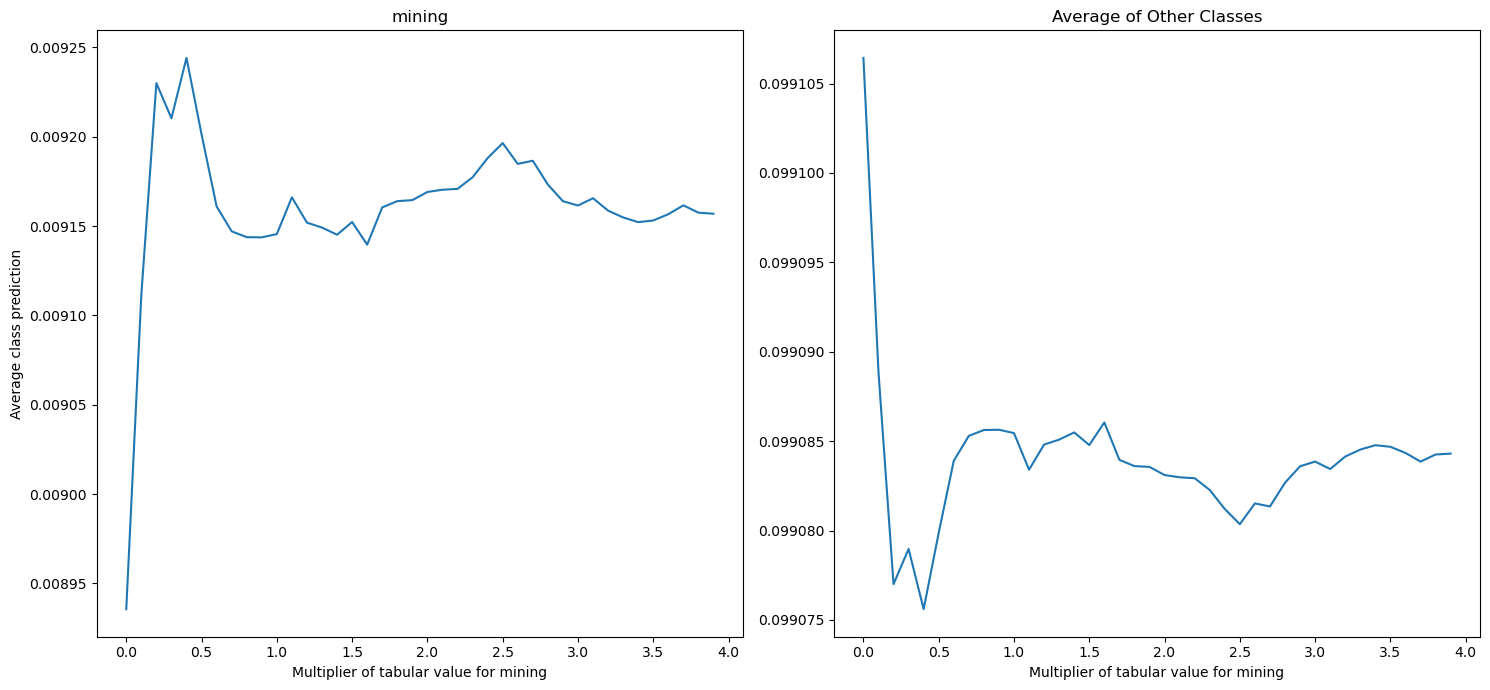

In [23]:

_all_mean_probs_mining = np.stack(all_mean_probs_mining)

cls_name = 'mining'

# Adjust grid size for two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)

# Separate 'rubber' and other classes
palm_oil_index = LABEL_MAPPING.get(cls_name)
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != cls_name]

# Plot for 'rubber'
axs[0].plot(coeffs, _all_mean_probs_mining[:, palm_oil_index])
axs[0].set_title(cls_name)
axs[0].set_ylabel('Average class prediction')
axs[0].set_xlabel(f'Multiplier of tabular value for {cls_name}')

# Plot for average of other classes
average_probs = np.mean(_all_mean_probs_mining[:, other_classes_idx], axis=1)
axs[1].plot(coeffs, average_probs)
axs[1].set_title('Average of Other Classes')
axs[1].set_xlabel(f'Multiplier of tabular value for {cls_name}')

# Tight layout
plt.tight_layout()
plt.show()

### urban

In [26]:
model.eval()

preds_batches = []
targets_batches = []

all_mean_probs_urban = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,6] = 1*coeff


        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs_urban.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


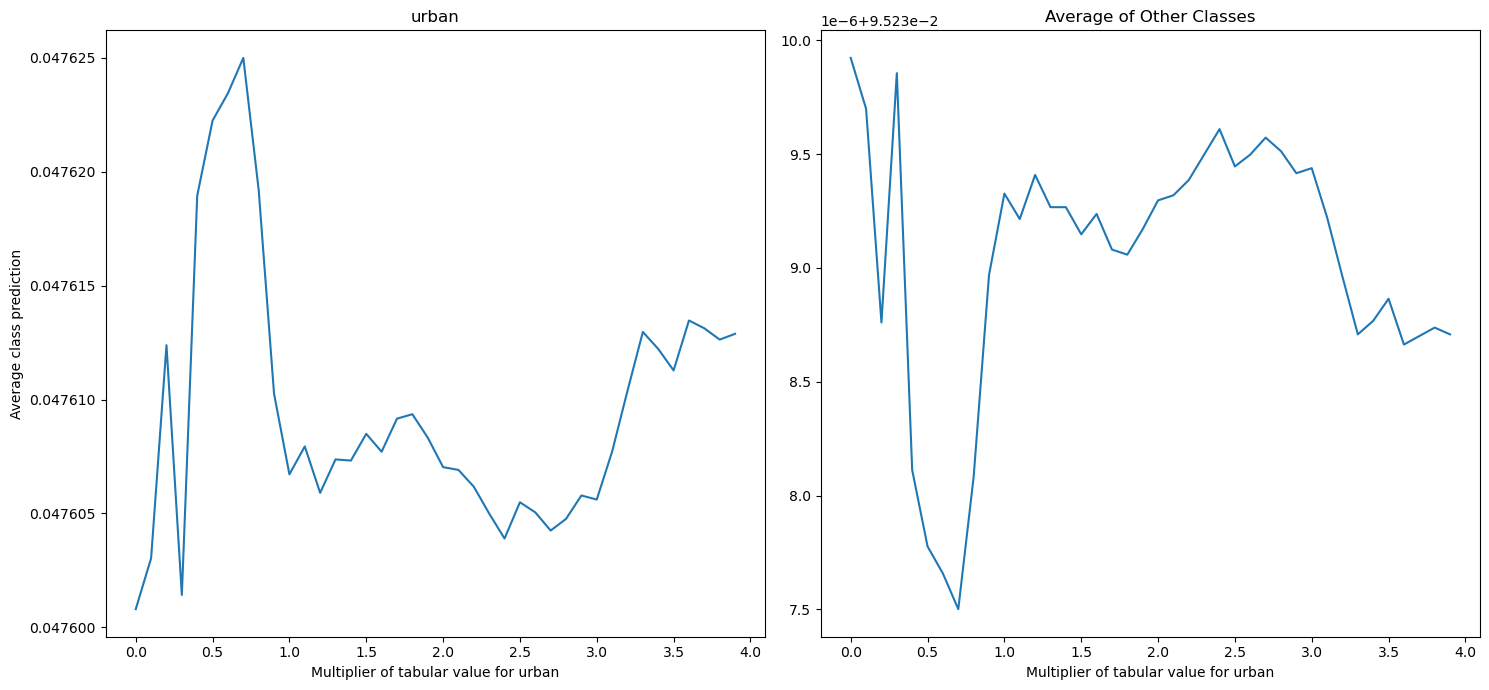

In [28]:

_all_mean_probs_urban = np.stack(all_mean_probs_mining)

cls_name = 'urban'

# Adjust grid size for two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)

# Separate 'rubber' and other classes
palm_oil_index = LABEL_MAPPING.get(cls_name)
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != cls_name]

# Plot for 'rubber'
axs[0].plot(coeffs, _all_mean_probs_urban[:, palm_oil_index])
axs[0].set_title(cls_name)
axs[0].set_ylabel('Average class prediction')
axs[0].set_xlabel(f'Multiplier of tabular value for {cls_name}')

# Plot for average of other classes
average_probs = np.mean(_all_mean_probs_urban[:, other_classes_idx], axis=1)
axs[1].plot(coeffs, average_probs)
axs[1].set_title('Average of Other Classes')
axs[1].set_xlabel(f'Multiplier of tabular value for {cls_name}')

# Tight layout
plt.tight_layout()
plt.show()

## Instead of multiplying provided values (doesnt work when no-data token), just impute values 

In [38]:
model.eval()

preds_batches = []
targets_batches = []

all_mean_probs = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,8] = coeff



        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


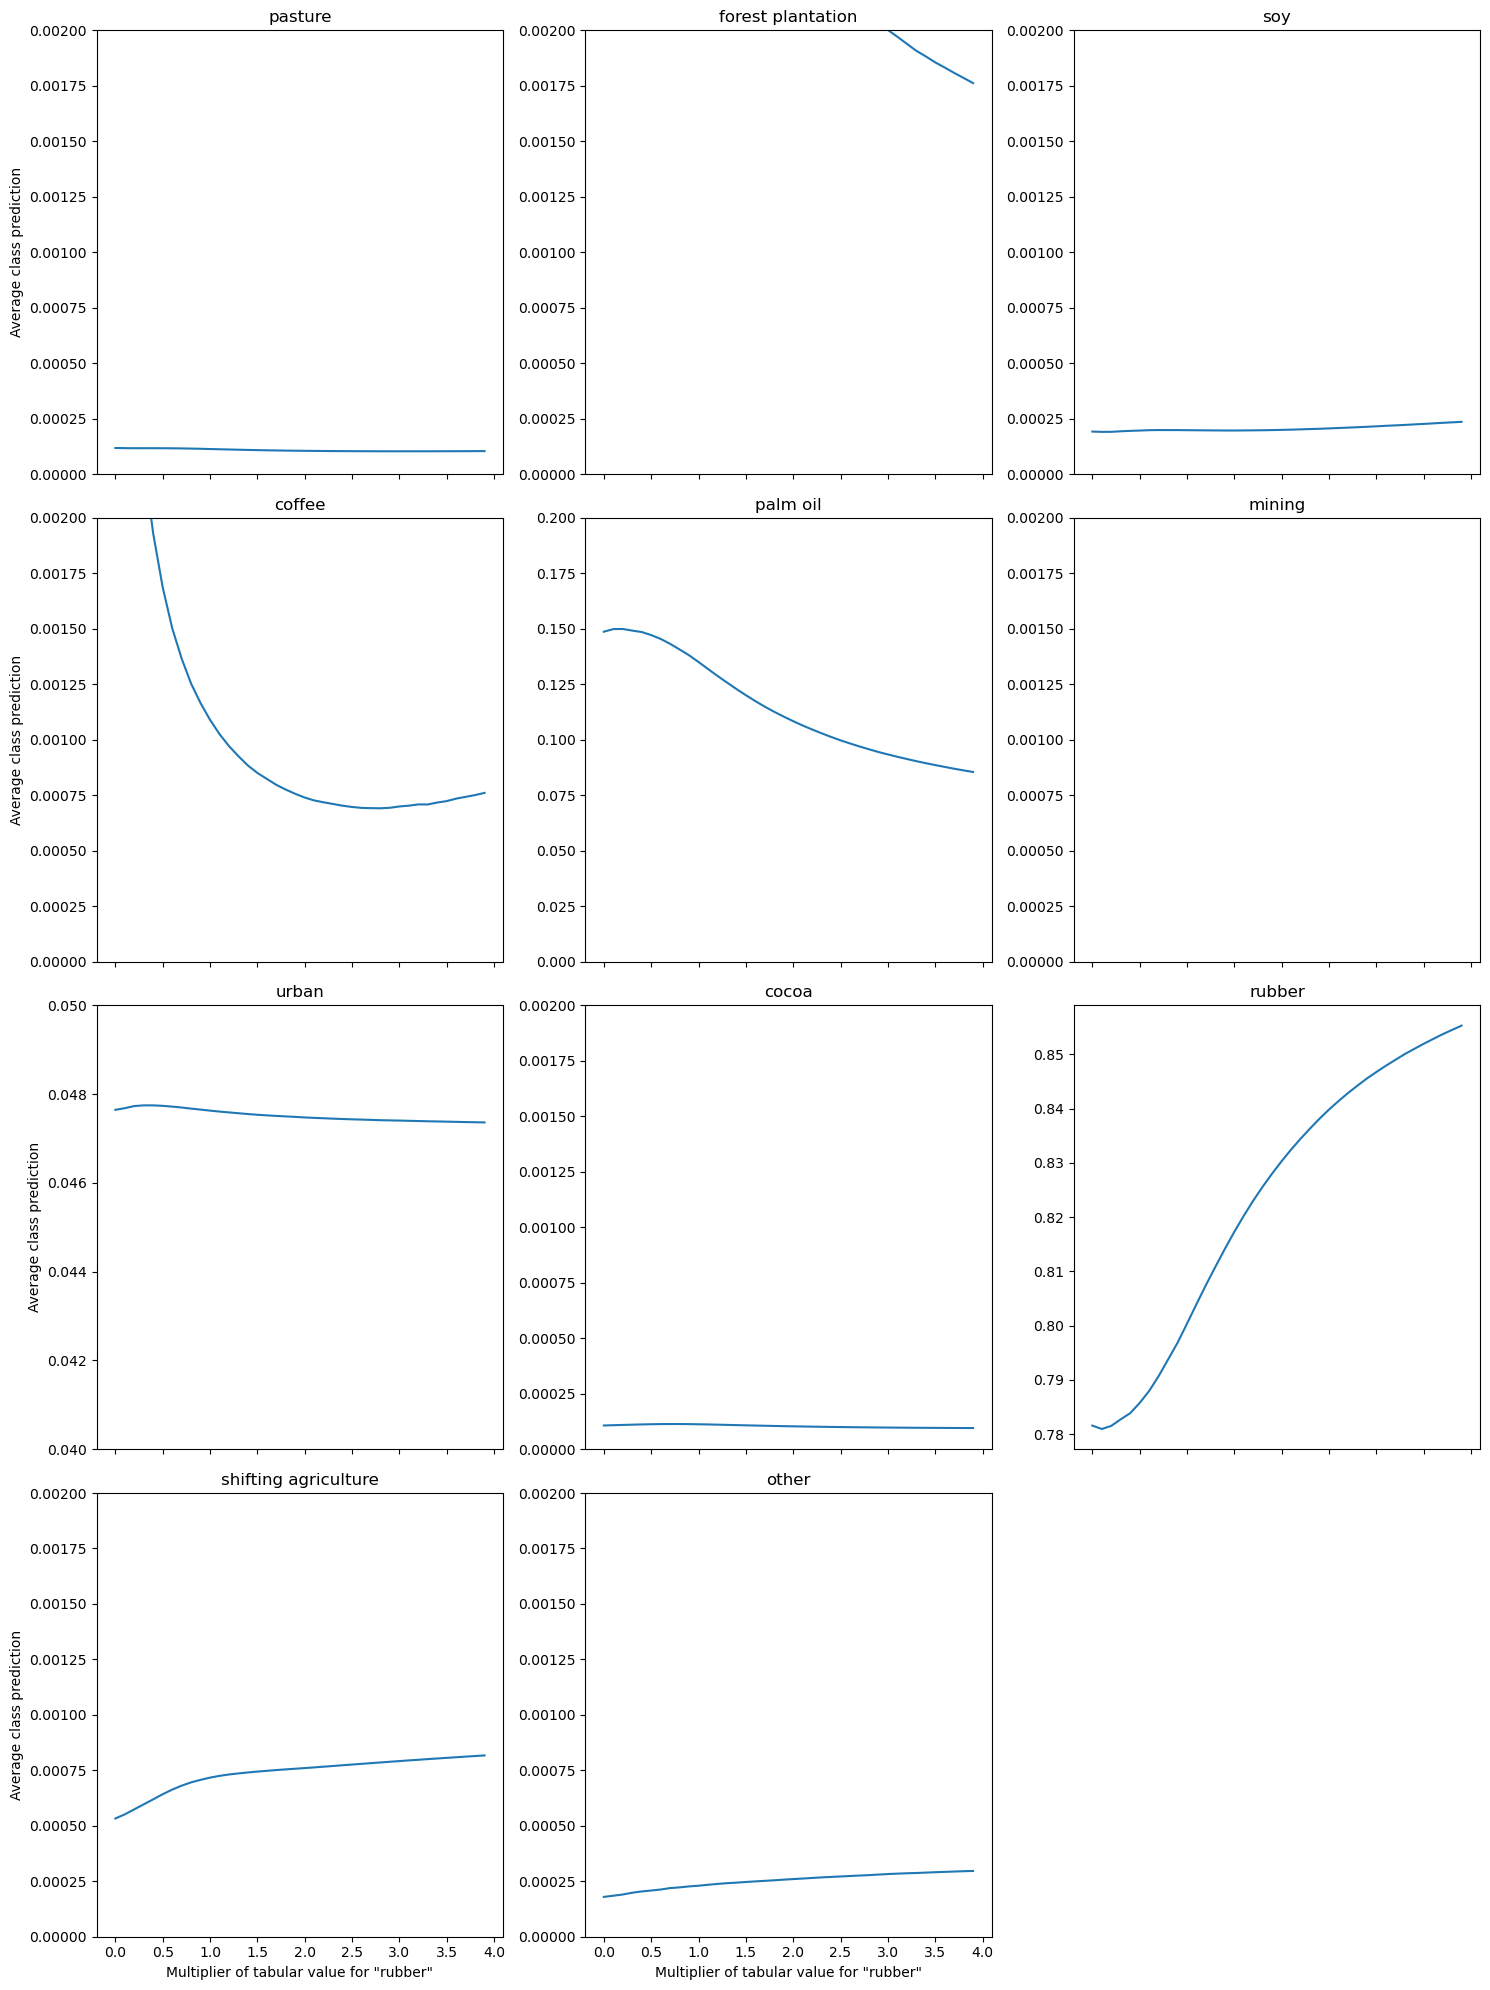

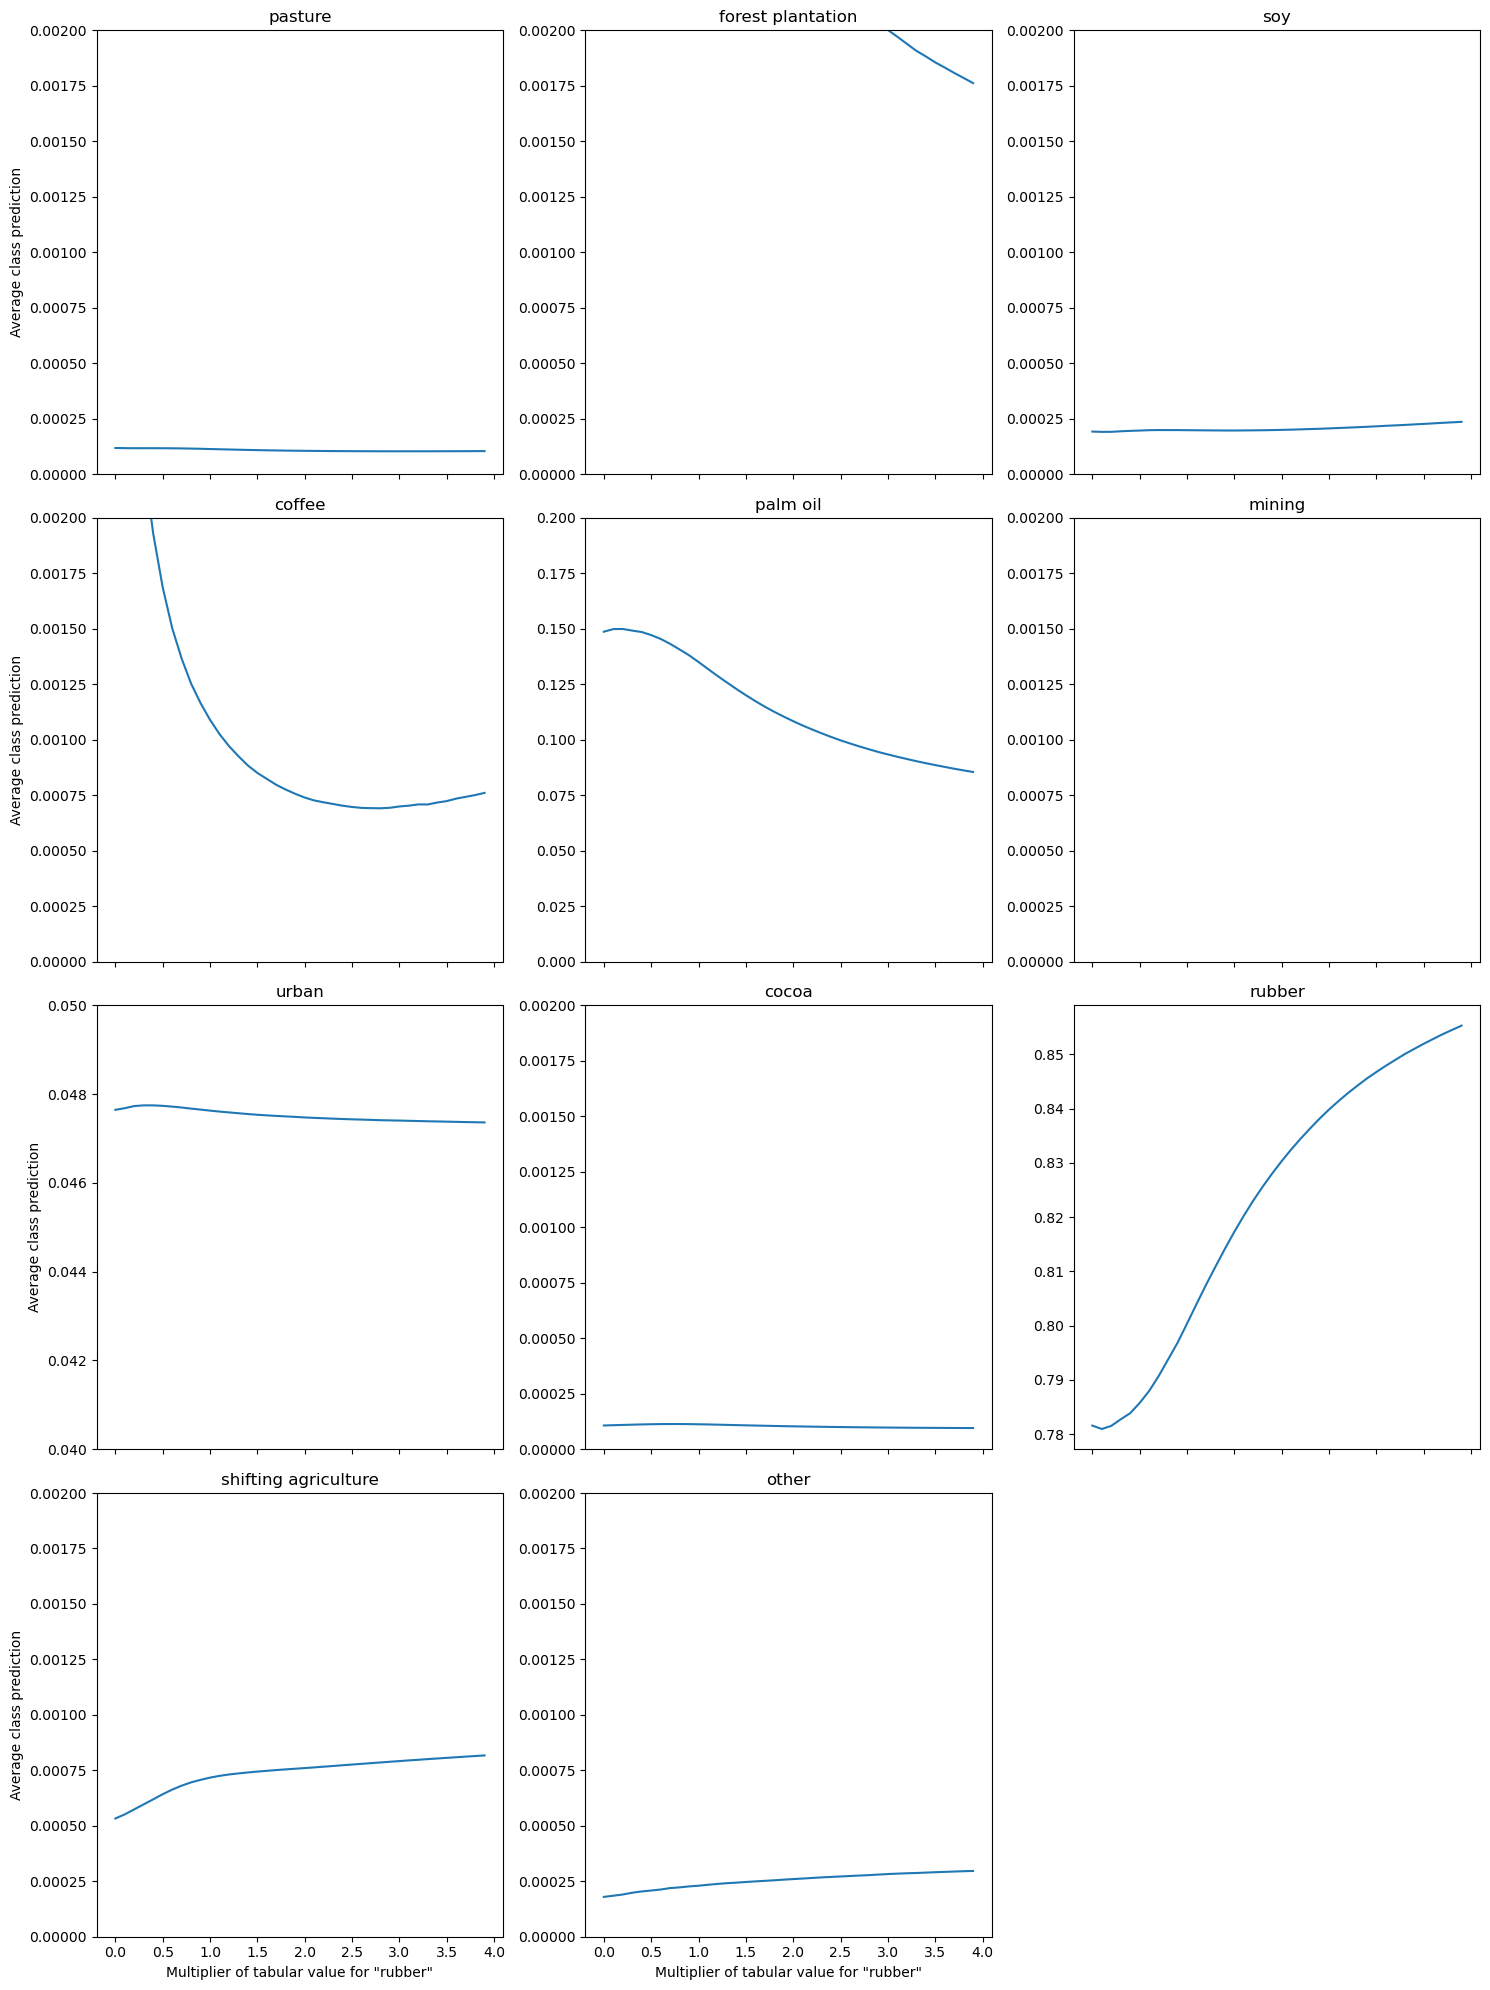

In [39]:
_all_mean_probs = np.stack(all_mean_probs)
coeffs = [coef/10 for coef in range(40)]

# Adjust grid size as needed; here we're using a 4x3 grid to accommodate up to 12 subplots
fig, axs = plt.subplots(4, 3, figsize=(15, 20), sharex=True)

limits = {}

#x_axis_vals = 

# Loop through LABEL_MAPPING and plot each on its own subplot
for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    row = idx // 3
    col = idx % 3
    axs[row, col].plot(coeffs, _all_mean_probs[:, cls_idx])
    axs[row, col].set_title(name)
    if name not in ['rubber']:

        if name == 'palm oil':
            
            axs[row, col].set_ylim(0, 0.2)
        elif name == 'urban':
            axs[row, col].set_ylim(0.04, 0.05)
        else:
            axs[row, col].set_ylim(0, 0.002)
    #axs[row, col].legend(loc='upper right')
    
    #axs[row, col].set_xticks(x_indices)
    #axs[row, col].set_xticklabels(x_axis_vals)
    if idx in [0,3,6,9]:
        axs[row, col].set_ylabel('Average class prediction')
    if idx in [9,10,11]:
        axs[row, col].set_xlabel('Multiplier of tabular value for "rubber"')
    
# Hide any unused subplots if the grid has extra spaces
for i in range(len(LABEL_MAPPING), 12):
    fig.delaxes(axs.flat[i])

#plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()
# Adjust grid size as needed; here we're using a 4x3 grid to accommodate up to 12 subplots
fig, axs = plt.subplots(4, 3, figsize=(15, 20), sharex=True)

limits = {}

#x_axis_vals = 

# Loop through LABEL_MAPPING and plot each on its own subplot
for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    row = idx // 3
    col = idx % 3
    axs[row, col].plot(coeffs, _all_mean_probs[:, cls_idx])
    axs[row, col].set_title(name)
    if name not in ['rubber']:

        if name == 'palm oil':
            
            axs[row, col].set_ylim(0, 0.2)
        elif name == 'urban':
            axs[row, col].set_ylim(0.04, 0.05)
        else:
            axs[row, col].set_ylim(0, 0.002)
    #axs[row, col].legend(loc='upper right')
    
    #axs[row, col].set_xticks(x_indices)
    #axs[row, col].set_xticklabels(x_axis_vals)
    if idx in [0,3,6,9]:
        axs[row, col].set_ylabel('Average class prediction')
    if idx in [9,10,11]:
        axs[row, col].set_xlabel('Multiplier of tabular value for "rubber"')
    
# Hide any unused subplots if the grid has extra spaces
for i in range(len(LABEL_MAPPING), 12):
    fig.delaxes(axs.flat[i])

#plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()

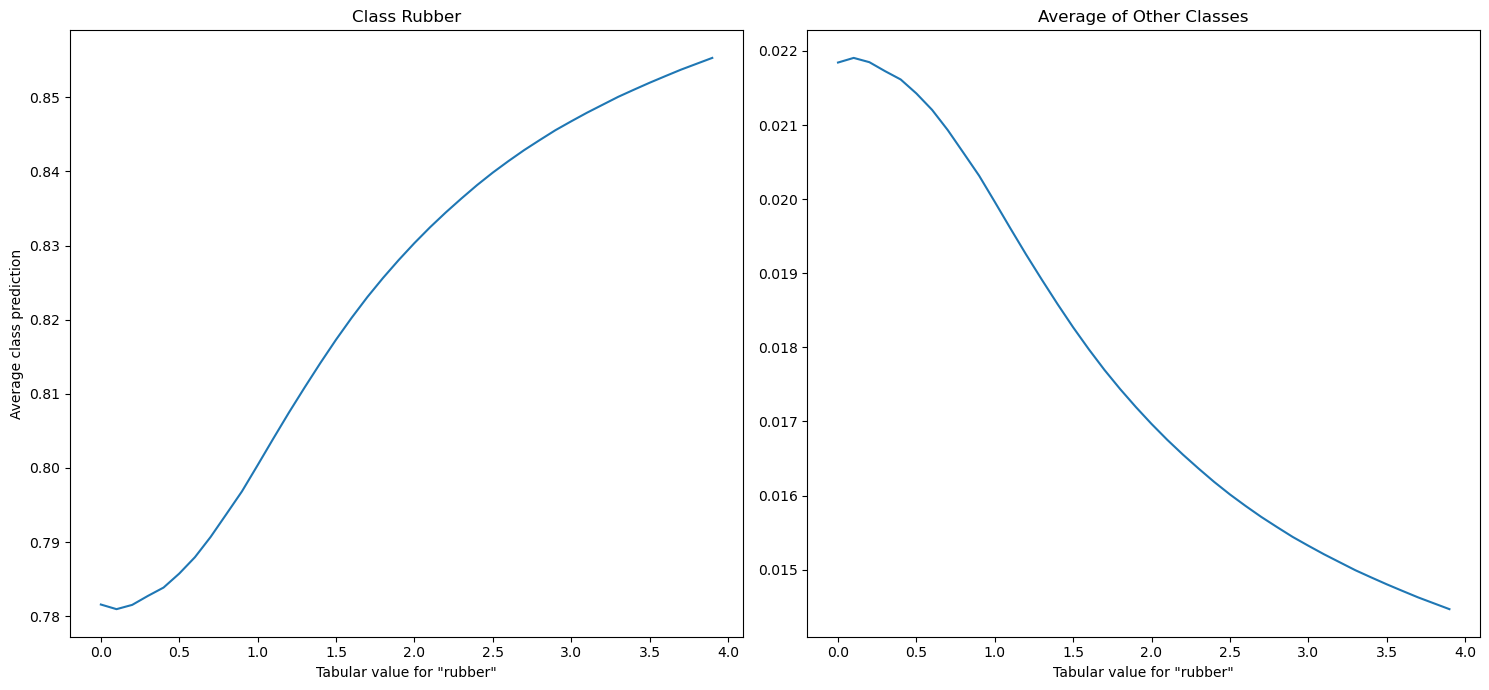

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# Adjust grid size for two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)

# Separate 'rubber' and other classes
rubber_idx = LABEL_MAPPING.get('rubber')
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != 'rubber']

# Plot for 'rubber'
axs[0].plot(coeffs, _all_mean_probs[:, rubber_idx])
axs[0].set_title('Class Rubber')
axs[0].set_ylabel('Average class prediction')
axs[0].set_xlabel('Tabular value for "rubber"')

# Plot for average of other classes
average_probs = np.mean(_all_mean_probs[:, other_classes_idx], axis=1)
axs[1].plot(coeffs, average_probs)
axs[1].set_title('Average of Other Classes')
axs[1].set_xlabel('Tabular value for "rubber"')

# Tight layout
plt.tight_layout()
plt.show()

# Ghana

In [93]:
ghana = df.loc[df.country == 'Ghana']

In [100]:
ghana.to_csv('../data/tmp/ghana_tmp.csv',   index=False)
config['data']['annotation_file'] = '../data/tmp/ghana_tmp.csv'
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [101]:

model.eval()

preds_batches = []
targets_batches = []

all_mean_probs = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,8] = expansion_rates_batch[:,8]*coeff



        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


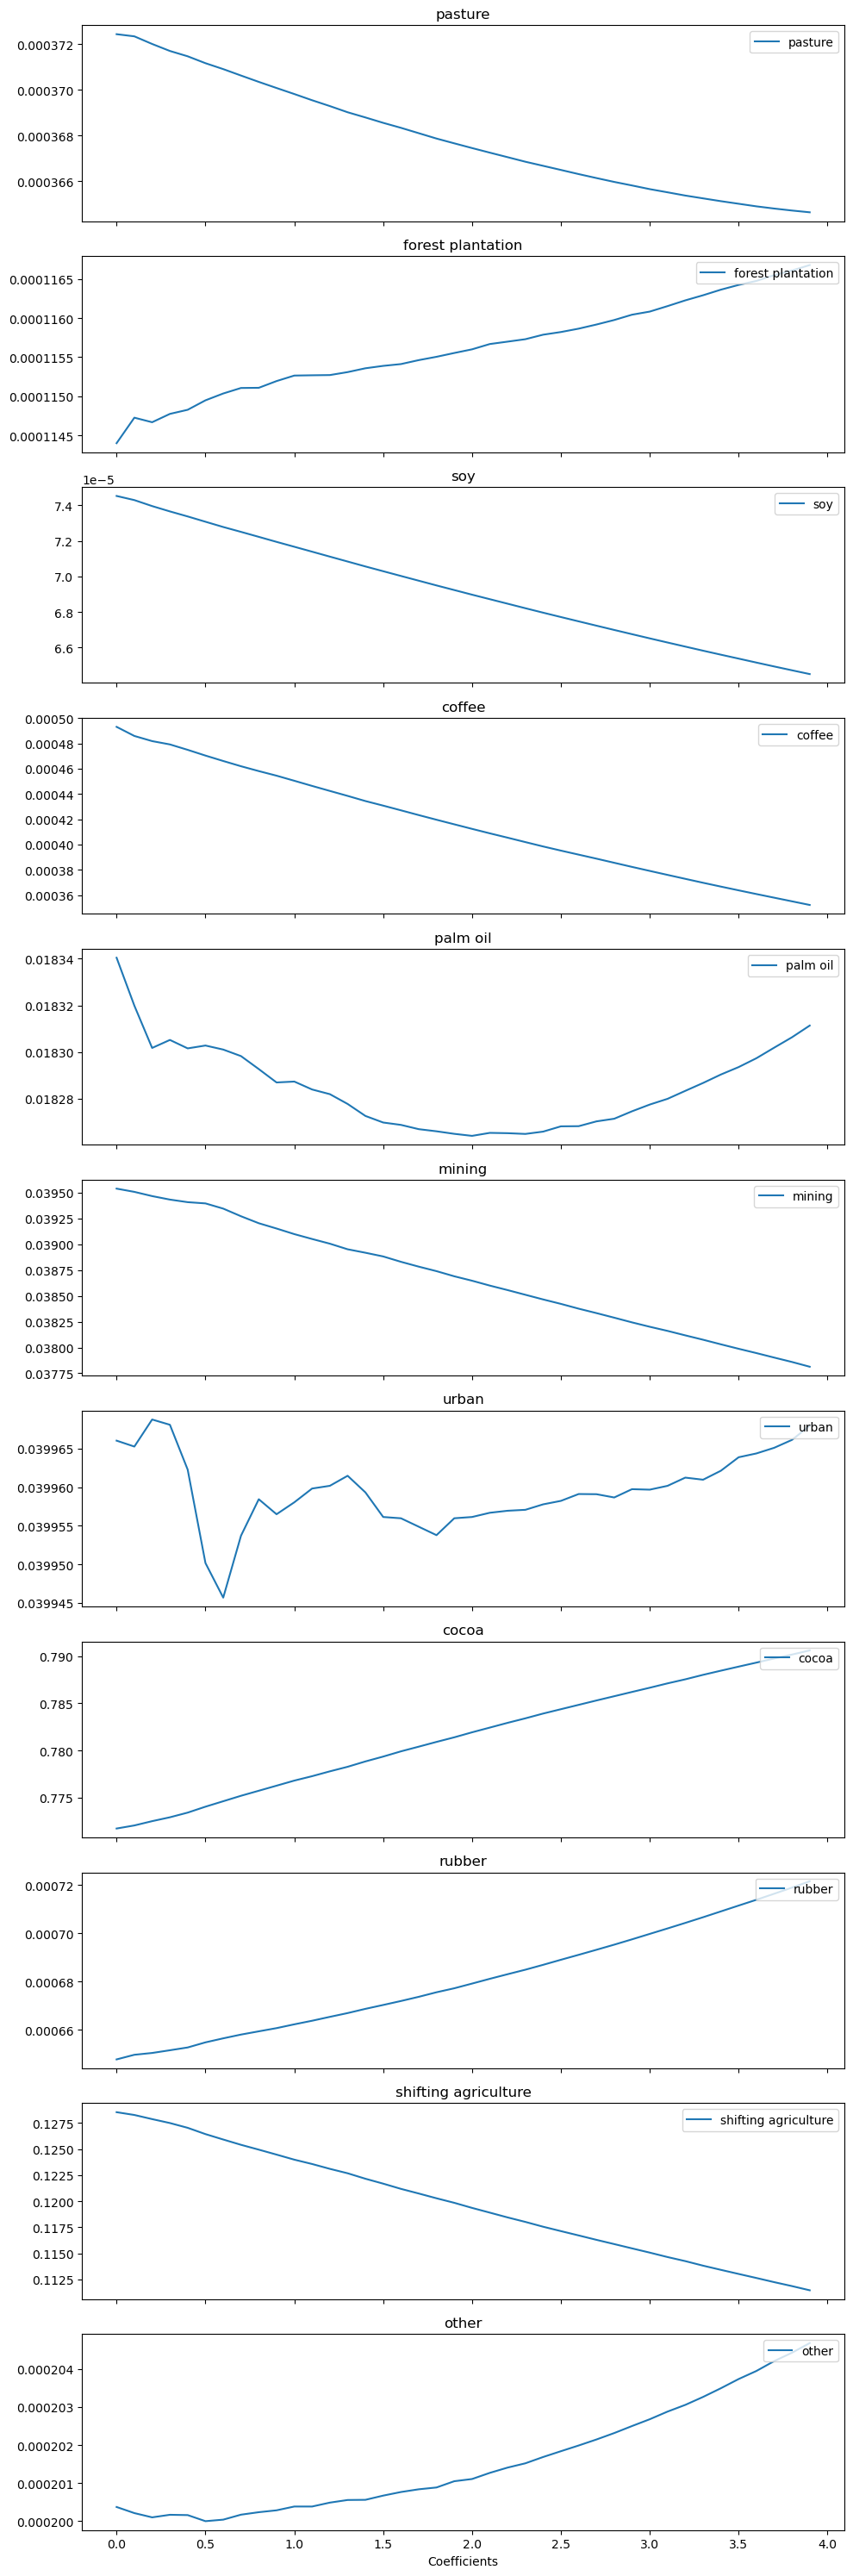

In [102]:
_all_mean_probs_ghana_rubber = np.stack(all_mean_probs)

fig, axs = plt.subplots(11, 1, figsize=(10, 30), sharex=True)

for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    axs[idx].plot(coeffs, _all_mean_probs_ghana_rubber[:, cls_idx], label=name)
    axs[idx].set_title(name)
    axs[idx].legend(loc='upper right')

plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()

### Cocoa

In [103]:

model.eval()

preds_batches = []
targets_batches = []

all_mean_probs = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,7] = expansion_rates_batch[:,7]*coeff



        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


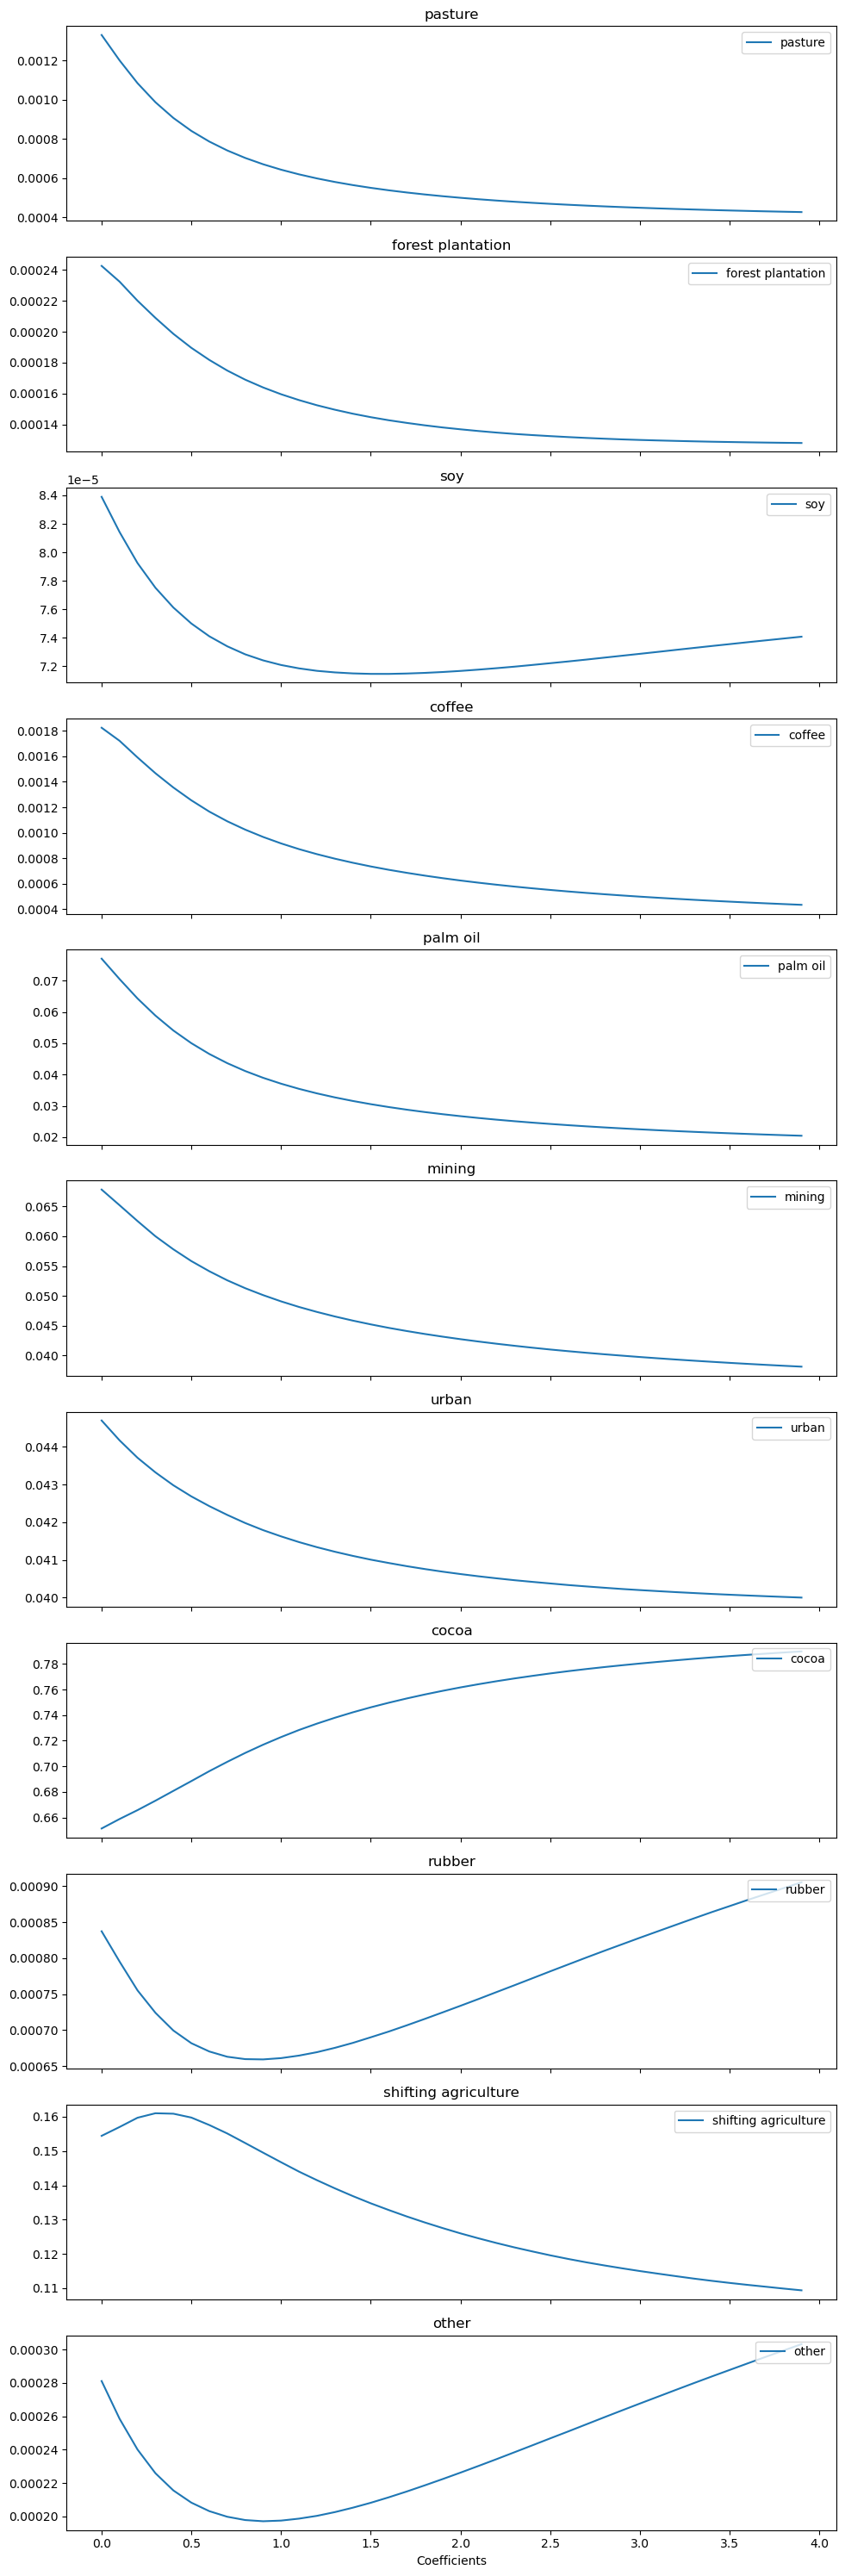

In [104]:
_all_mean_probs_ghana_cocoa = np.stack(all_mean_probs)

fig, axs = plt.subplots(11, 1, figsize=(10, 30), sharex=True)

for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    axs[idx].plot(coeffs, _all_mean_probs_ghana_cocoa[:, cls_idx], label=name)
    axs[idx].set_title(name)
    axs[idx].legend(loc='upper right')

plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()

# Brazil

In [106]:
brazil = df.loc[df.country == 'Brazil']
brazil.to_csv('../data/tmp/brazil_tmp.csv',   index=False)
config['data']['annotation_file'] = '../data/tmp/brazil_tmp.csv'
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

### Cocoa

In [110]:

model.eval()

preds_batches = []
targets_batches = []

all_mean_probs = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,7] = expansion_rates_batch[:,7]*coeff



        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


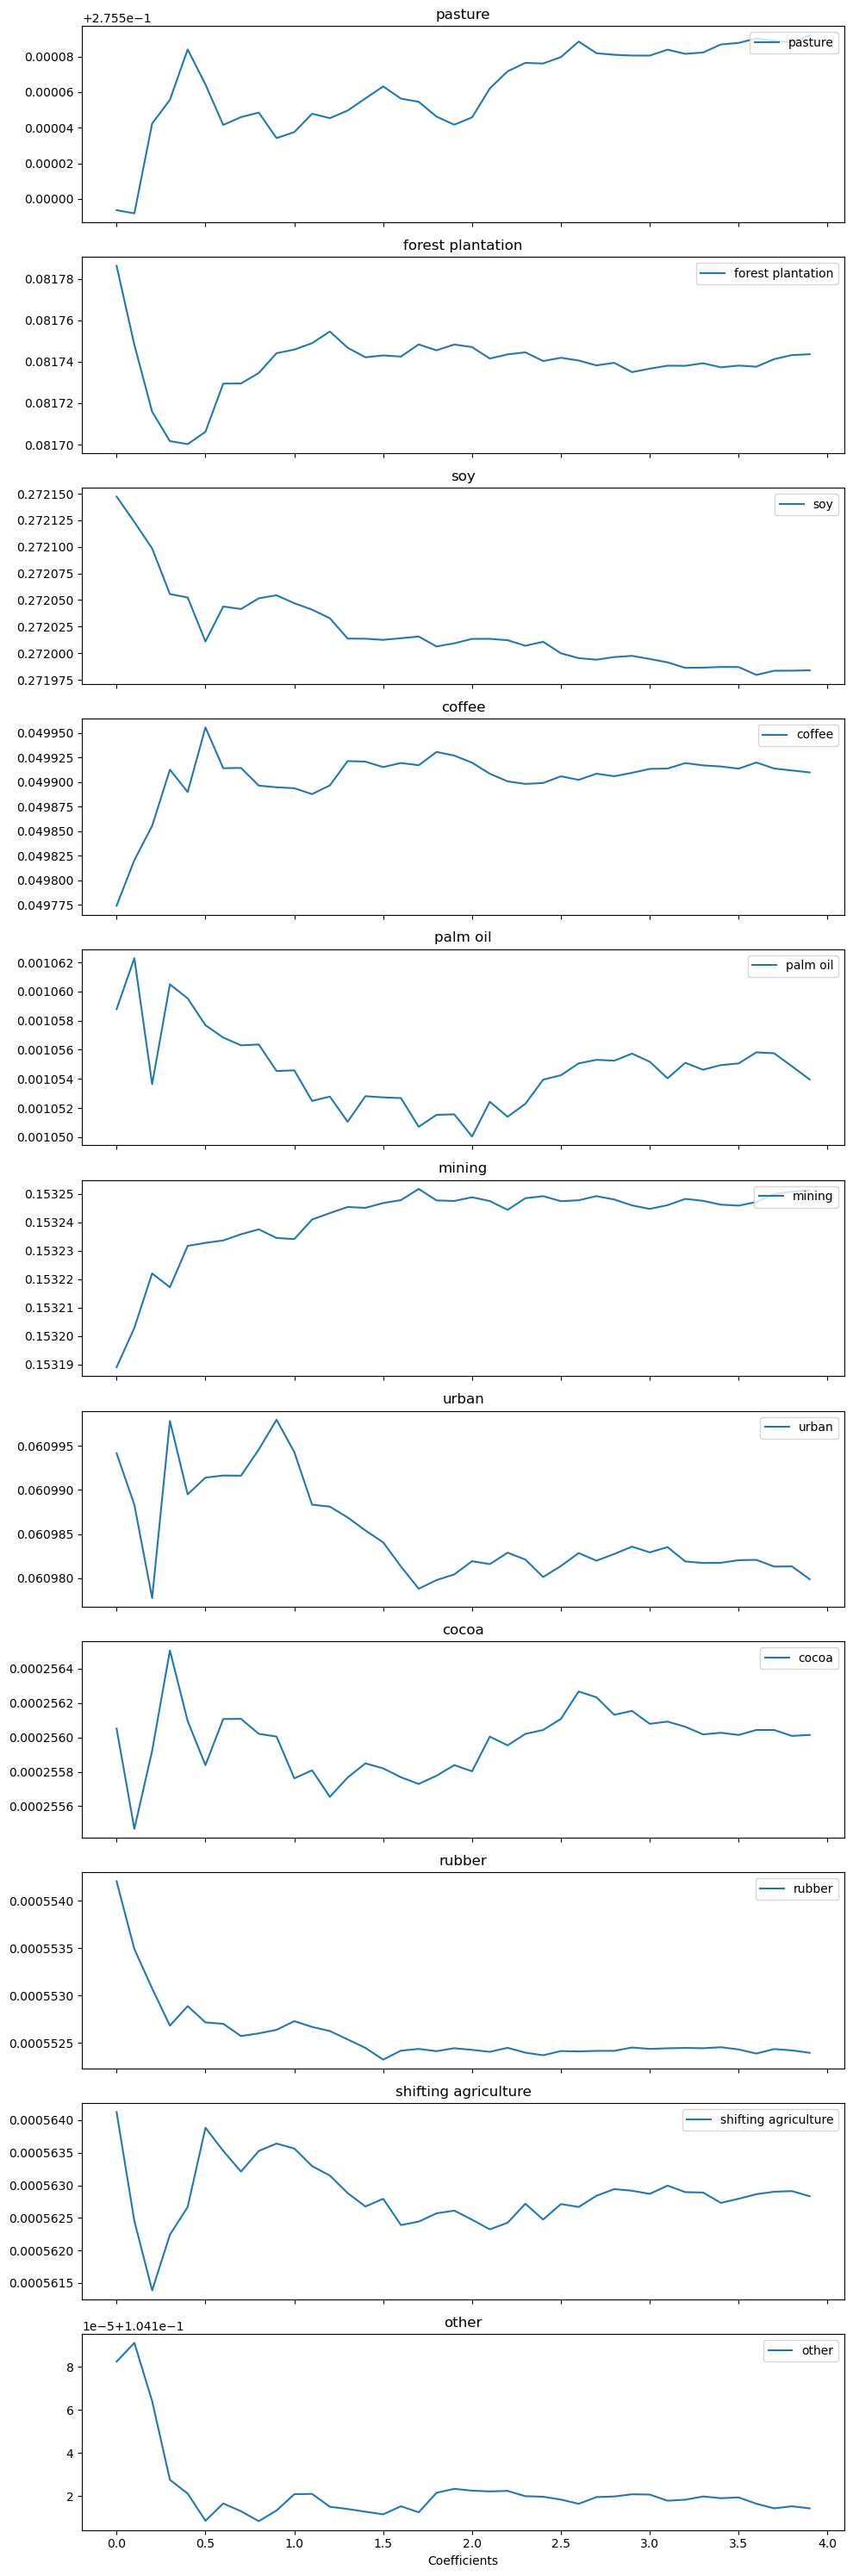

In [111]:
_all_mean_probs_brazil_cocoa = np.stack(all_mean_probs)

fig, axs = plt.subplots(11, 1, figsize=(10, 30), sharex=True)

for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    axs[idx].plot(coeffs, _all_mean_probs_brazil_cocoa[:, cls_idx], label=name)
    axs[idx].set_title(name)
    axs[idx].legend(loc='upper right')

plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()

### Pasture

In [112]:

model.eval()

preds_batches = []
targets_batches = []

all_mean_probs = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,0] = expansion_rates_batch[:,0]*coeff



        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


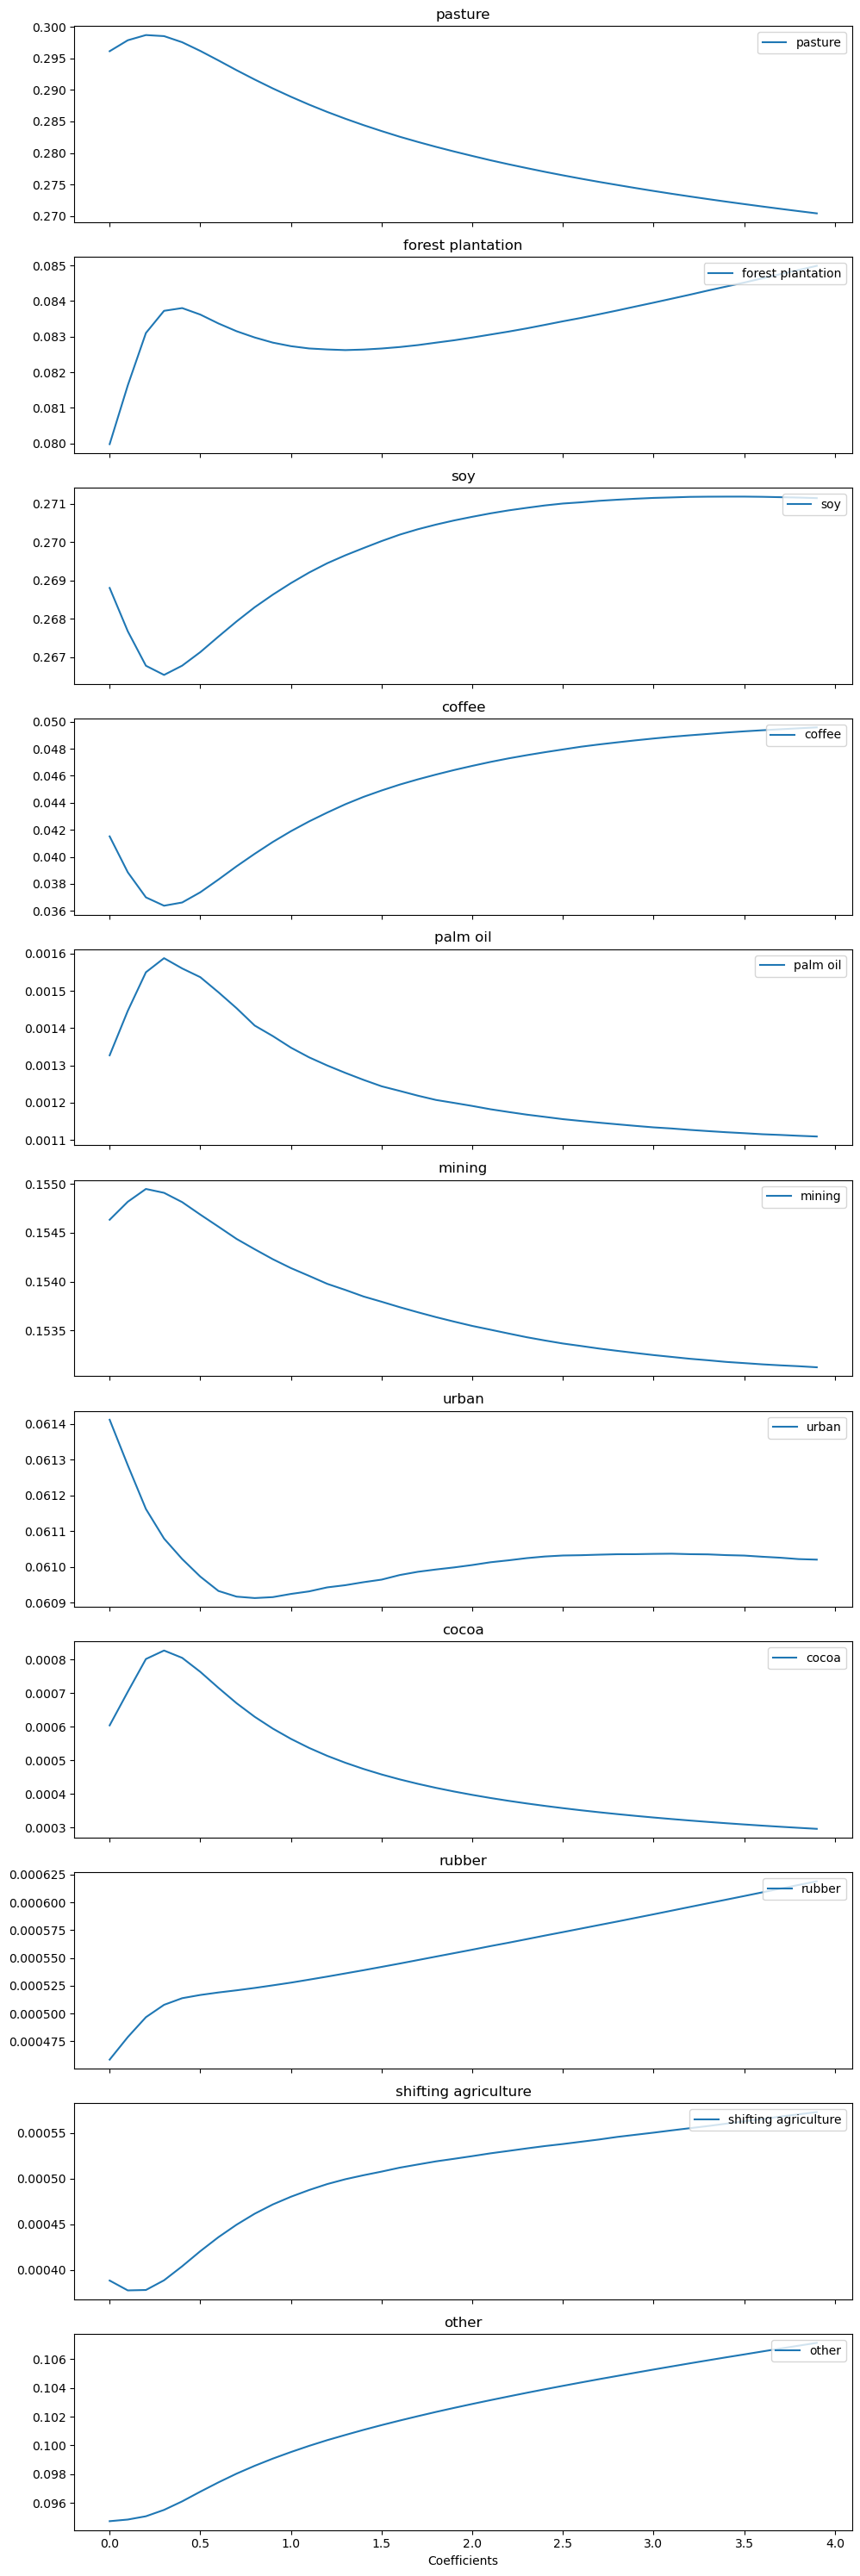

In [113]:
_all_mean_probs_brazil_pasture = np.stack(all_mean_probs)

fig, axs = plt.subplots(11, 1, figsize=(10, 30), sharex=True)

for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    axs[idx].plot(coeffs, _all_mean_probs_brazil_pasture[:, cls_idx], label=name)
    axs[idx].set_title(name)
    axs[idx].legend(loc='upper right')

plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()

## Soy

In [115]:

model.eval()

preds_batches = []
targets_batches = []

all_mean_probs = []

for coeff in range(40):
    coeff = coeff/10
    print(coeff)
    for data_batch, labels_batch in val_dl:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

        expansion_rates_batch[:,2] = expansion_rates_batch[:,2]*coeff



        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)

    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
    mean_probs = probabilities.mean(axis=0).numpy()
    all_mean_probs.append(mean_probs)

    preds = probabilities.argmax(dim=1).numpy()


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9


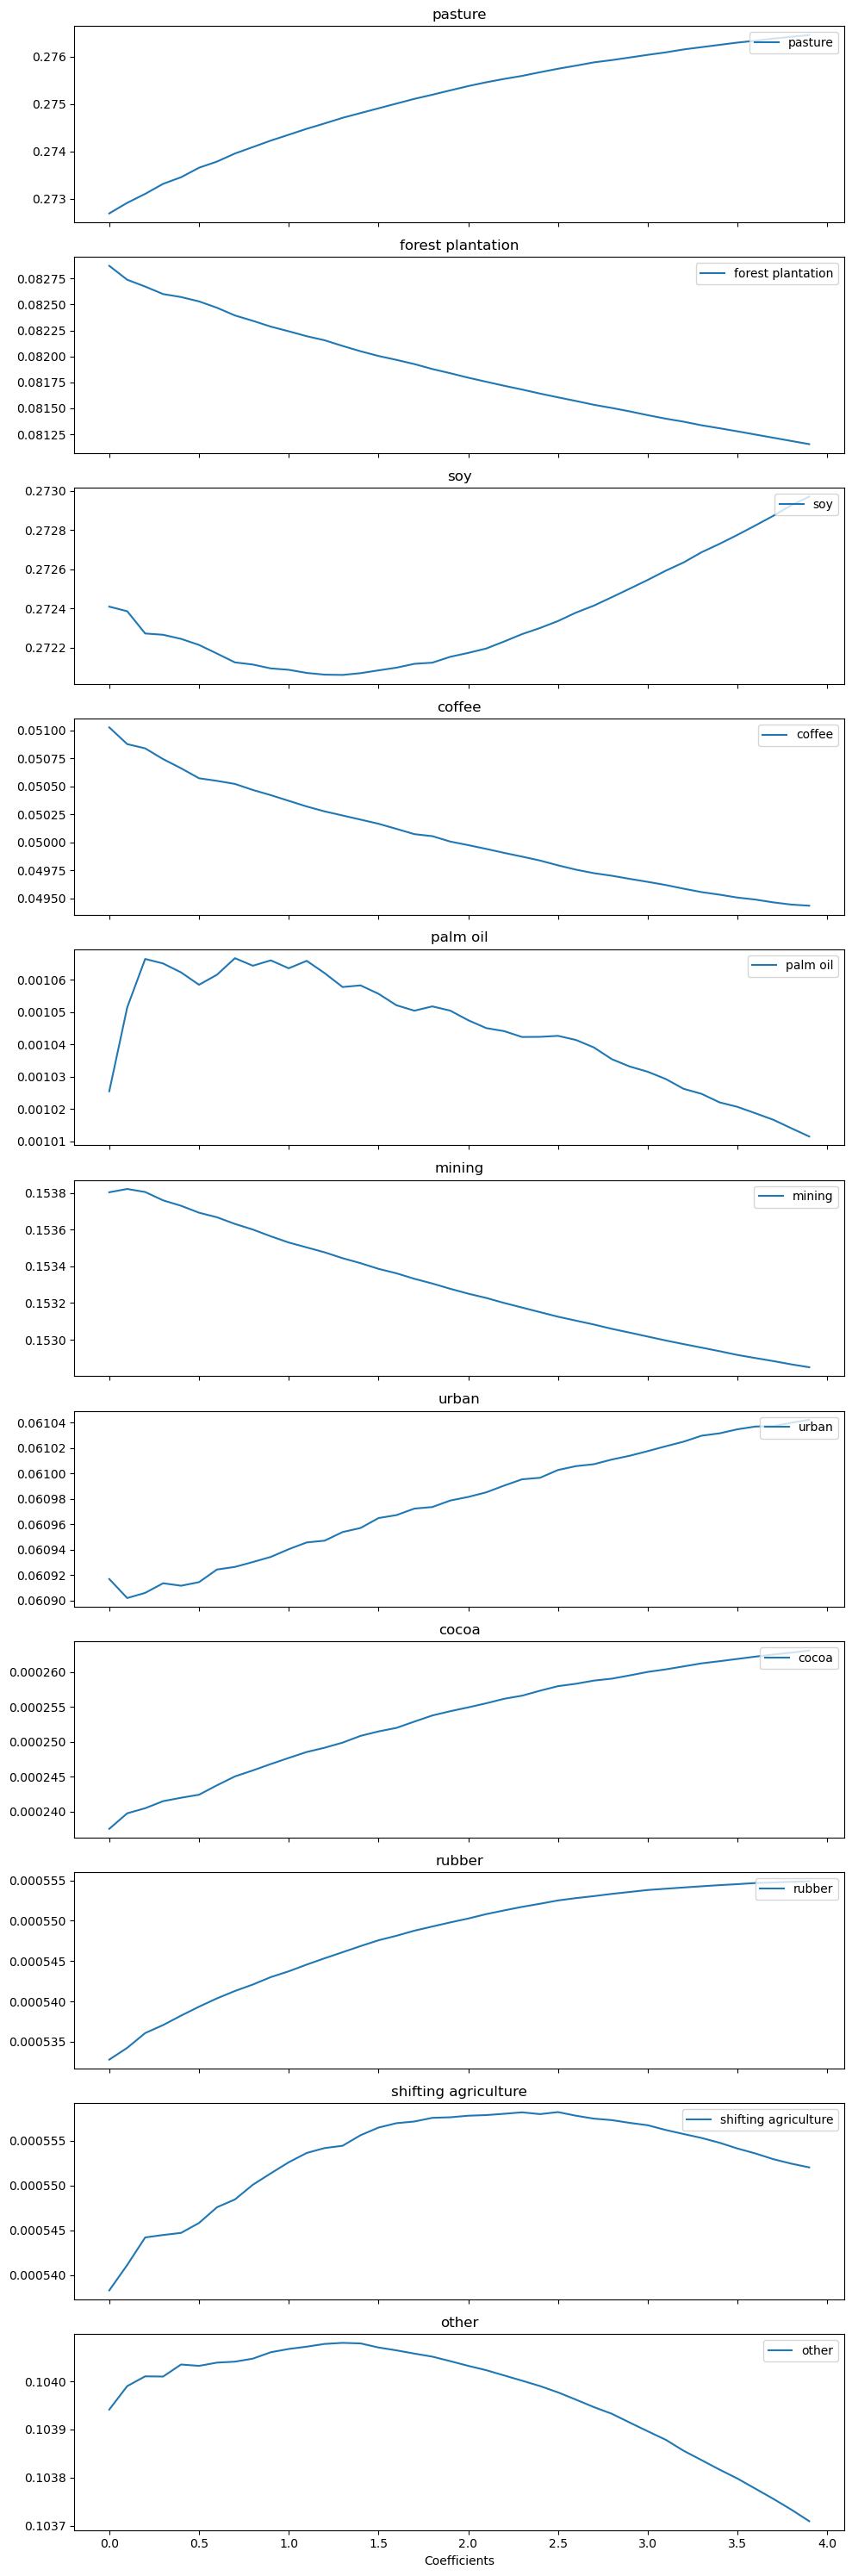

In [116]:
_all_mean_probs_brazil_soy = np.stack(all_mean_probs)

fig, axs = plt.subplots(11, 1, figsize=(10, 30), sharex=True)

for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
    axs[idx].plot(coeffs, _all_mean_probs_brazil_soy[:, cls_idx], label=name)
    axs[idx].set_title(name)
    axs[idx].legend(loc='upper right')

plt.xlabel("Coefficients")
plt.tight_layout()
plt.show()

In [119]:
df.loc[df.driver == 'soy'].country.value_counts()

country
Brazil      2639
Paraguay     187
Bolivia      151
Name: count, dtype: int64

In [61]:
x,y = next(iter(val_dl))

In [131]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()
    
def plot_images_with_tmf(data, tmf, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(16, 16))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.permute(1, 2, 0).numpy())
    ax[n_images].set_xticks([])
    ax[n_images].set_yticks([])
    
    fig.tight_layout()
    plt.show()
    

